# Quickstart — escenarios de generación eólica diaria

El target del pipeline es la **energía total generada durante cada día**, en MWh.

```text
viento horario [m/s]
        ↓
curva de potencia
        ↓
potencia horaria [MW]
        ↓
suma de 24 intervalos de 1 h
        ↓
energía diaria [MWh]
        ↓
TimesFM
        ↓
Schaake Shuffle
        ↓
escenarios de generación diaria [MWh]
```

Para un día completo:

\[
E_d=\sum_{h=1}^{24}P_{d,h}\Delta t,
\qquad \Delta t=1\,h.
\]

`POWER_MW` se conserva como diagnóstico de potencia media diaria, pero **TimesFM utiliza `ENERGY_MWH`**.

## 1. Entorno

Desde la raíz:

```powershell
uv sync
```

En VS Code selecciona:

```text
.venv\Scripts\python.exe
```

In [18]:
from __future__ import annotations

import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image as IPythonImage, display

from wind_scenarios.data import (
    DEFAULT_DATA_PATH,
    DEFAULT_TARGET_COLUMN,
    PROJECT_ROOT,
)
from wind_scenarios.evaluation import (
    load_ground_truth,
    save_ground_truth,
)

print("Python:", sys.executable)
print("Proyecto:", PROJECT_ROOT)
print("Dataset:", DEFAULT_DATA_PATH)
print("Target:", DEFAULT_TARGET_COLUMN)

Python: c:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\.venv\Scripts\python.exe
Proyecto: C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration
Dataset: C:\Users\Maximiliano\Desktop\ExpWindScenariesGeneration\data\power_ab_daily.csv
Target: ENERGY_MWH


## 2. Preprocesar viento horario

El preprocesamiento transforma primero cada velocidad horaria a potencia. Luego suma la energía de los 24 intervalos horarios.

El resultado diario contiene:

```text
DATE,POWER_MW,ENERGY_MWH
```

donde `ENERGY_MWH` es el target.

In [19]:
def preprocess_daily_generation(
    *,
    input_path: str | Path = PROJECT_ROOT / "data" / "wind_hourly.csv",
    hourly_output: str | Path = PROJECT_ROOT / "data" / "power_ab_hourly.csv",
    daily_output: str | Path = DEFAULT_DATA_PATH,
    timestamp_column: str = "source_timestamp",
    wind_column: str = "wind_ab",
    n_turbines: float = 1.0,
    availability: float = 1.0,
    electrical_efficiency: float = 1.0,
    incomplete_day_policy: str = "error",
) -> pd.DataFrame:
    command = [
        sys.executable,
        str(PROJECT_ROOT / "scripts" / "preprocess_power_ab.py"),
        "--input",
        str(Path(input_path)),
        "--hourly_output",
        str(Path(hourly_output)),
        "--daily_output",
        str(Path(daily_output)),
        "--timestamp_column",
        timestamp_column,
        "--wind_column",
        wind_column,
        "--n_turbines",
        str(n_turbines),
        "--availability",
        str(availability),
        "--electrical_efficiency",
        str(electrical_efficiency),
        "--incomplete_day_policy",
        incomplete_day_policy,
    ]

    subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        check=True,
    )

    return pd.read_csv(
        daily_output,
        parse_dates=["DATE"],
    )

In [20]:
# Ejecutar cuando sea necesario reconstruir el dataset:
#
daily_generation = preprocess_daily_generation()
display(daily_generation.head())

,DATE,POWER_MW,ENERGY_MWH
0,1980-01-07,3.499890,83.997350
1,1980-01-08,3.499924,83.998170
2,1980-01-09,3.499692,83.992620
3,1980-01-10,3.316288,79.590900
4,1980-01-11,3.212687,77.104485


## 3. Generar escenarios de energía diaria

In [21]:
def generate_energy_scenarios(
    origin: str,
    historical_method: str = "same_calendar_date",
    context_len: int = 32,
    horizon_len: int = 28,
    *,
    n_scenarios: int | None = None,
    window_radius_days: int = 15,
    min_start_distance_days: int = 0,
    selection: str = "closest",
    device: str = "auto",
    probability_grid_mode: str = "timesfm_support",
    crossing_policy: str = "error",
    energy_bounds_policy: str = "clip",
    energy_min_mwh: float = 0.0,
    energy_max_mwh: float | None = None,
    export_ground_truth: bool = True,
    data_path: str | Path = DEFAULT_DATA_PATH,
    target_column: str = DEFAULT_TARGET_COLUMN,
    output_root: str | Path = PROJECT_ROOT / "outputs" / "schaake",
) -> dict:
    origin_ts = pd.Timestamp(origin).normalize()
    data_path = Path(data_path)
    output_root = Path(output_root)

    command = [
        sys.executable,
        "-m",
        "wind_scenarios.cli.generate",
        "--origin",
        origin_ts.date().isoformat(),
        "--historical_method",
        historical_method,
        "--context_len",
        str(context_len),
        "--horizon_len",
        str(horizon_len),
        "--device",
        device,
        "--data_path",
        str(data_path),
        "--target_column",
        target_column,
        "--probability_grid_mode",
        probability_grid_mode,
        "--crossing_policy",
        crossing_policy,
        "--energy_bounds_policy",
        energy_bounds_policy,
        "--energy_min_mwh",
        str(energy_min_mwh),
        "--output_dir",
        str(output_root),
    ]

    if energy_max_mwh is not None:
        command.extend(
            [
                "--energy_max_mwh",
                str(energy_max_mwh),
            ]
        )

    if n_scenarios is not None:
        command.extend(
            [
                "--n_scenarios",
                str(n_scenarios),
            ]
        )

    if historical_method == "moving_window":
        command.extend(
            [
                "--window_radius_days",
                str(window_radius_days),
                "--min_start_distance_days",
                str(min_start_distance_days),
                "--selection",
                selection,
            ]
        )

    subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        check=True,
    )

    output_dir = (
        output_root
        / origin_ts.date().isoformat()
    )

    ground_truth_path = None
    if export_ground_truth:
        ground_truth_path = save_ground_truth(
            origin=origin_ts,
            horizon_len=horizon_len,
            output_dir=output_dir,
            data_path=data_path,
            value_column=target_column,
        )

    paths = {
        "context": output_dir / "context.csv",
        "quantiles": output_dir / "timesfm_quantiles.csv",
        "historical": output_dir / "historical_trajectories.csv",
        "ranks": output_dir / "historical_ranks.csv",
        "energy_scenarios": output_dir / "energy_scenarios.csv",
        "run_config": output_dir / "run_config.json",
        "ground_truth": ground_truth_path,
    }

    result = {
        "origin": origin_ts,
        "output_dir": output_dir,
        "paths": paths,
        "context": pd.read_csv(
            paths["context"],
            parse_dates=["DATE"],
        ),
        "quantiles": pd.read_csv(
            paths["quantiles"],
            parse_dates=["DATE"],
        ),
        "energy_scenarios": pd.read_csv(
            paths["energy_scenarios"],
            index_col="scenario_id",
        ),
    }

    if ground_truth_path is not None:
        result["ground_truth"] = pd.read_csv(
            ground_truth_path,
            parse_dates=["DATE"],
        )

    return result

## 4. Caso base

In [29]:
result = generate_energy_scenarios(
    origin="2014-04-01",
    historical_method="same_calendar_date",
    context_len=32,
    horizon_len=28,
    energy_bounds_policy="none",
)

## 5. Revisar resultados

In [30]:
display(result["context"].head())
display(result["quantiles"].head())
display(result["energy_scenarios"].head())
display(result["ground_truth"].head())

,DATE,ENERGY_MWH
0,2014-02-28,73.625780
1,2014-03-01,41.670090
2,2014-03-02,29.033096
3,2014-03-03,59.711777
4,2014-03-04,83.302010


,DATE,q10,q20,q30,q40,q50,q60,q70,q80,q90
0,2014-04-01,23.158550,35.395256,42.956291,48.593658,53.216721,57.572353,61.723400,66.800056,73.842873
1,2014-04-02,33.237083,46.885178,54.769833,61.636868,66.713585,71.416229,76.385147,81.104446,87.676743
2,2014-04-03,39.518673,52.840073,62.461388,69.105179,74.433311,79.251442,83.697578,89.062912,94.695686
3,2014-04-04,39.930477,55.481560,64.348732,70.155449,75.898041,80.668228,84.479813,89.241348,95.550301
4,2014-04-05,39.652534,54.054062,62.941971,70.089653,75.164452,79.597664,84.042694,88.335022,93.484322


,2014-04-01,2014-04-02,2014-04-03,2014-04-04,2014-04-05,2014-04-06,2014-04-07,2014-04-08,2014-04-09,2014-04-10,...,2014-04-19,2014-04-20,2014-04-21,2014-04-22,2014-04-23,2014-04-24,2014-04-25,2014-04-26,2014-04-27,2014-04-28
scenario_id,,,,,,,,,,,,,,,,,,,,,
scenario_001,62.031076,64.867506,68.501198,90.961972,92.236007,90.378429,61.150720,34.002899,36.950119,43.414382,...,45.106968,39.963257,64.073991,63.105870,67.903561,65.697643,59.255458,45.450560,40.283427,69.430127
scenario_002,56.912409,71.867949,72.495809,61.661710,58.094020,41.259231,67.456122,73.410413,73.829632,81.447260,...,57.126824,68.183748,85.135503,84.507507,88.402362,57.591985,38.687424,40.854772,52.348163,68.294139
scenario_003,29.091499,62.406067,77.353391,63.811328,50.126373,56.864563,72.391931,72.466441,69.854893,91.813713,...,81.702205,75.887618,58.714852,61.512836,81.394923,86.744655,61.372271,50.046348,54.511275,72.527528
scenario_004,54.800587,67.283602,87.924811,81.014736,77.851247,78.440991,83.222158,76.968180,65.569370,90.527144,...,67.406686,44.050554,40.439915,57.161785,64.787070,73.409014,71.607651,62.948789,82.028840,82.231525
scenario_005,45.347902,33.237083,59.545838,81.938756,89.739376,89.070525,73.316726,75.263916,82.343315,76.594561,...,53.120205,66.632434,76.102420,78.012894,77.804939,82.177223,82.878444,86.995148,85.666132,75.198576


,DATE,ENERGY_MWH,LEAD_DAY
0,2014-04-01,10.442184,1
1,2014-04-02,26.790600,2
2,2014-04-03,2.973312,3
3,2014-04-04,35.481230,4
4,2014-04-05,19.289272,5


## 6. Visualización

In [31]:
def visualize_result(
    result: dict,
    *,
    mode: str = "single",
    scenario_number: int = 1,
    all_quantiles: bool = False,
    export_all: bool = False,
    display_plot: bool = True,
    data_path: str | Path = DEFAULT_DATA_PATH,
    target_column: str = DEFAULT_TARGET_COLUMN,
) -> Path:
    output_dir = Path(
        result["output_dir"]
    )

    command = [
        sys.executable,
        "-m",
        "wind_scenarios.cli.visualize",
        "--input_dir",
        str(output_dir),
        "--data_path",
        str(Path(data_path)),
        "--target_column",
        target_column,
        "--mode",
        mode,
    ]

    if all_quantiles:
        command.append(
            "--all_quantiles"
        )

    if export_all:
        command.append(
            "--export_all"
        )
    elif mode == "single":
        command.extend(
            [
                "--scenario_number",
                str(scenario_number),
            ]
        )

    subprocess.run(
        command,
        cwd=PROJECT_ROOT,
        check=True,
    )

    if export_all:
        return output_dir / (
            "energy_scenario_plots_all_quantiles"
            if all_quantiles
            else "energy_scenario_plots"
        )

    if mode == "fan":
        plot_path = output_dir / (
            "energy_scenario_fan_all_quantiles.png"
            if all_quantiles
            else "energy_scenario_fan.png"
        )
    else:
        suffix = (
            "_all_quantiles"
            if all_quantiles
            else ""
        )
        plot_path = (
            output_dir
            / f"scenario_{scenario_number:03d}{suffix}.png"
        )

    if display_plot:
        display(
            IPythonImage(
                filename=str(plot_path)
            )
        )

    return plot_path

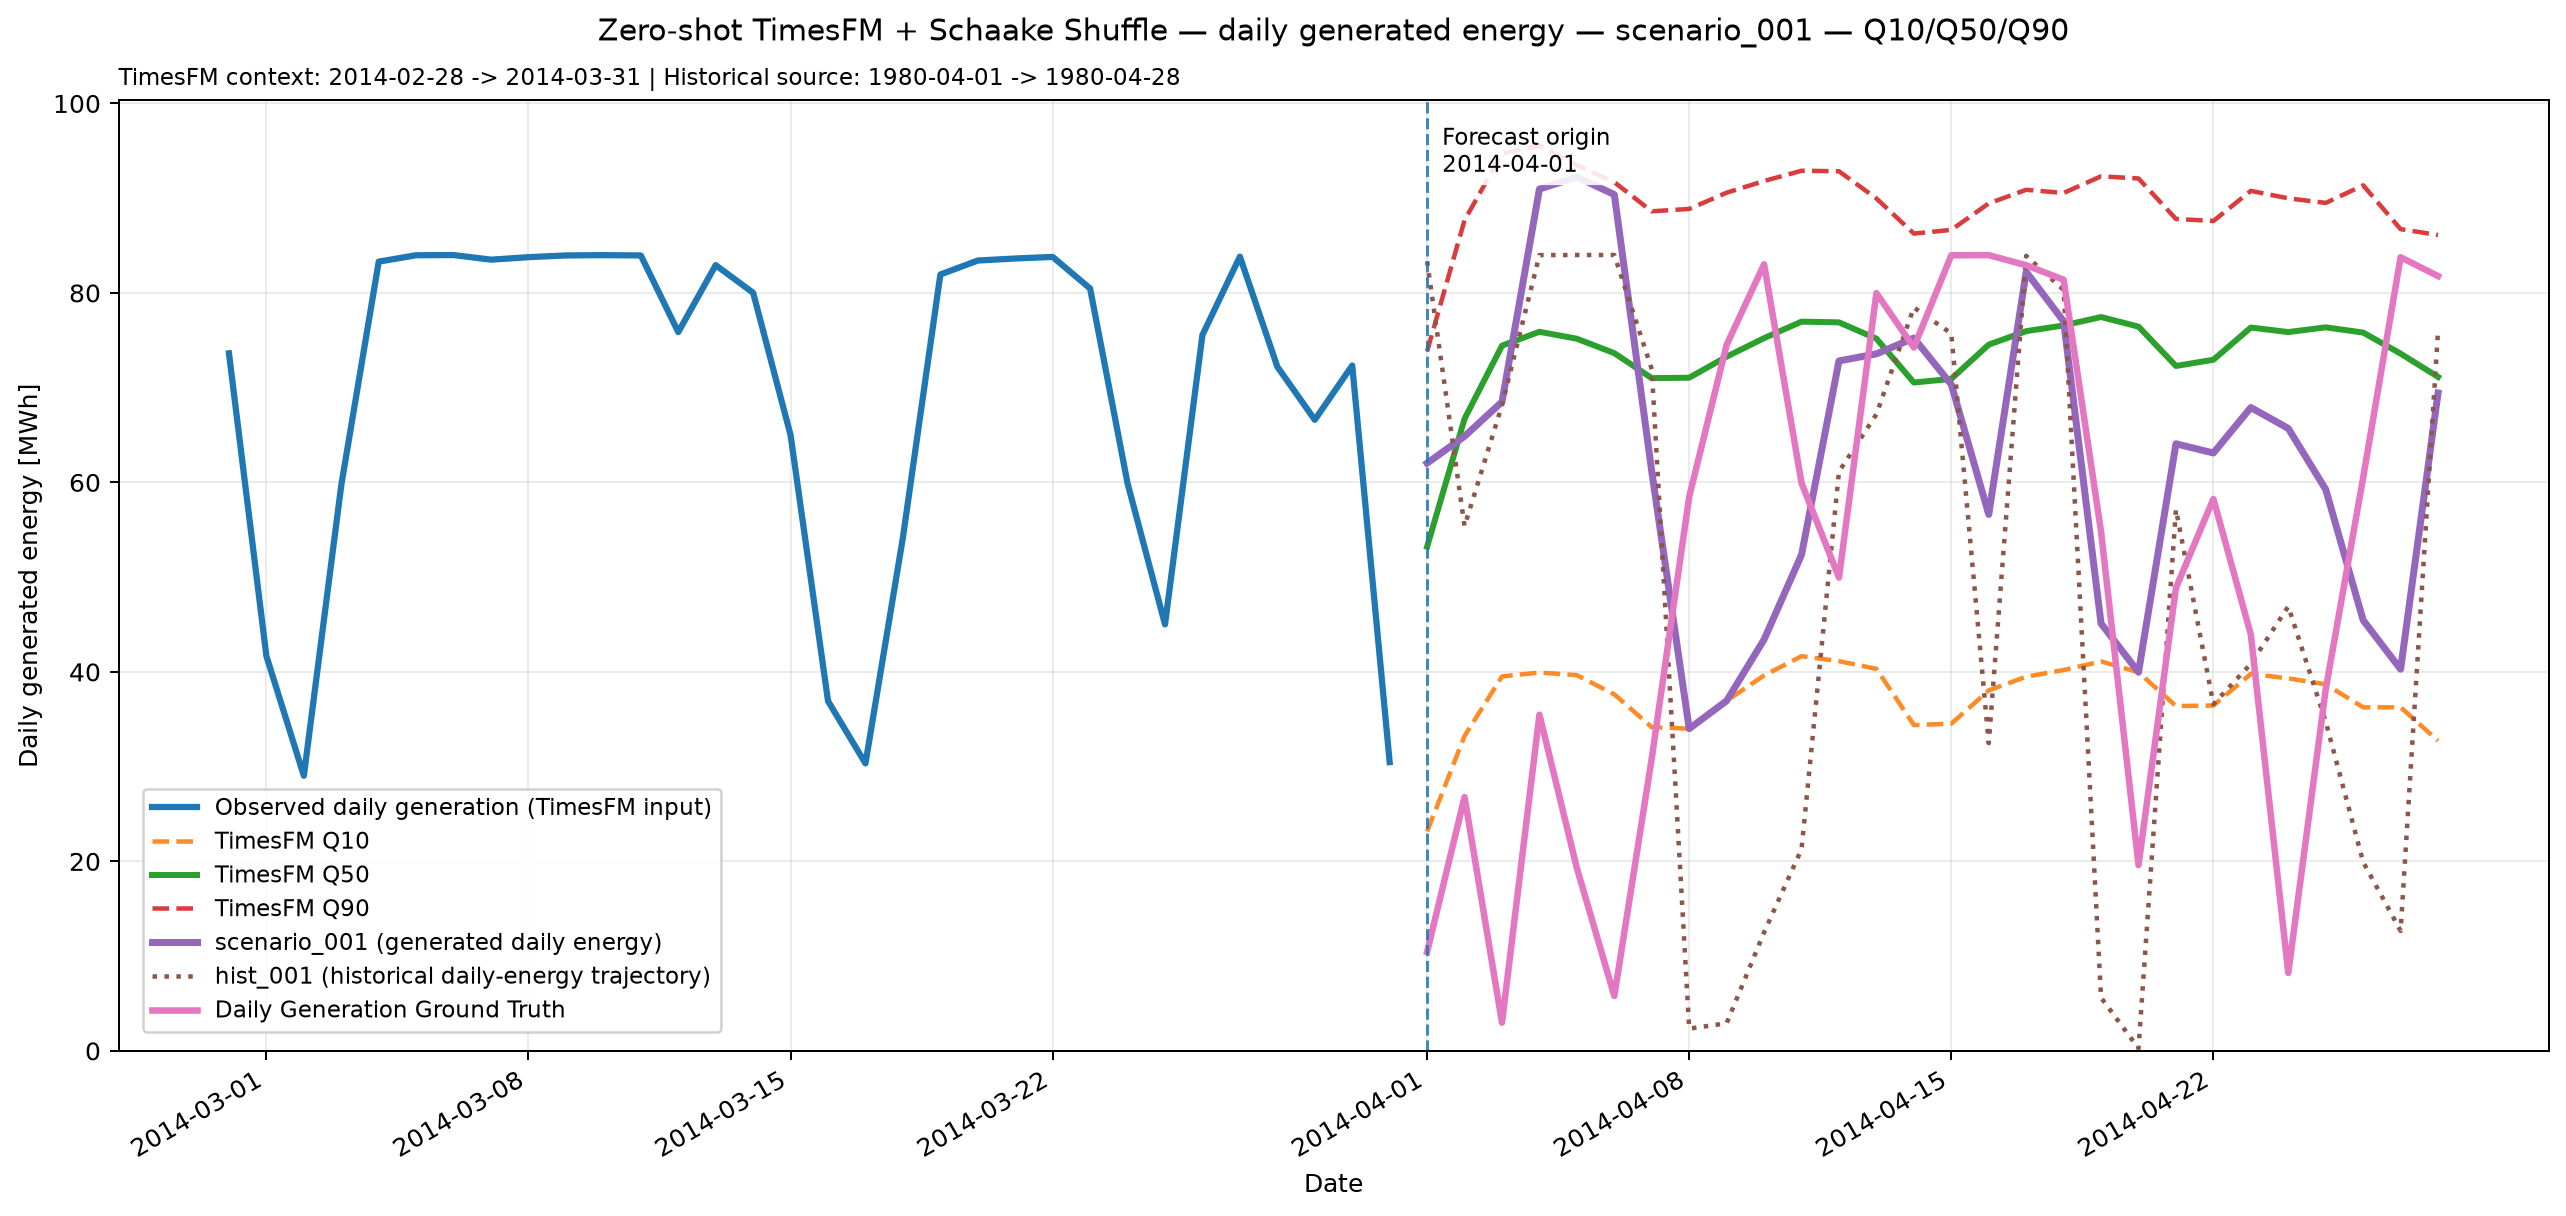

WindowsPath('C:/Users/Maximiliano/Desktop/ExpWindScenariesGeneration/outputs/schaake/2014-04-01/scenario_001.png')

In [32]:
# Escenario 1 con Q10, Q50 y Q90.
visualize_result(
    result,
    mode="single",
    scenario_number=1,
    all_quantiles=False,
)

In [ ]:
# Exportar todos con Q10, Q50 y Q90:

visualize_result(
     result,
     mode="single",
     all_quantiles=False,
     export_all=True,
     display_plot=False,
)

# Exportar todos con Q10-Q90:
#
# visualize_result(
#     result,
#     mode="single",
#     all_quantiles=True,
#     export_all=True,
#     display_plot=False,
# )

## 7. Ejemplos alternativos

60 días:

```python
result_60 = generate_energy_scenarios(
    origin="2014-04-01",
    context_len=60,
    horizon_len=60,
)
```

100 escenarios:

```python
result_100 = generate_energy_scenarios(
    origin="2014-04-01",
    historical_method="moving_window",
    n_scenarios=100,
    window_radius_days=15,
    min_start_distance_days=7,
)
```